# Modelagem Preditiva & Engenharia de Features — ENEM 2023

**Projeto:** EduDataBR  
**Sprint:** 5 — Engenharia de Features & Machine Learning  
**Base Analítica:** `data/processed/enem_2023_analitico.parquet` ($N = 2.678.264$ casos completos)  

### Objetivos do Notebook:
1. **Engenharia de Features:** Construir features contextuais e demográficas ex-ante (`classe_renda`, `in_vulnerabilidade`, `in_idade_regular`) blindadas contra qualquer vazamento de dados (*data leakage*).
2. **Modelagem de Regressão:** Predizer a nota média geral nacional do candidato (`nu_nota_media_geral`) comparando baselines (`DummyRegressor`, `Ridge`) com algoritmos não-lineares baseados em árvores (`HistGradientBoostingRegressor`).
3. **Modelagem de Classificação:** Prever a probabilidade de o candidato alcançar a faixa de alto desempenho (`fl_alto_desempenho` — Percentil 80, $\ge 623$ pontos) com `DummyClassifier`, `LogisticRegression` e `HistGradientBoostingClassifier`.
4. **Interpretabilidade e Explicabilidade:** Mensurar a importância global e a contribuição marginal de cada fator socioeconômico através de **SHAP Values** (`TreeExplainer`).
5. **Persistência de Modelos:** Salvar os pipelines finais treinados (`models/regressor_enem2023.joblib` e `models/classificador_enem2023.joblib`) para consumo futuro pelo aplicativo interativo da Sprint 6.


## 1. Setup do Ambiente e Importação de Bibliotecas

Configuração do ambiente de execução, importação de bibliotecas para processamento numérico, modelagem de machine learning e visualização de dados.


In [1]:
import os
import time
import warnings
import joblib
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.ensemble import HistGradientBoostingRegressor, HistGradientBoostingClassifier
from sklearn.metrics import (
    r2_score,
    root_mean_squared_error,
    mean_absolute_error,
    roc_auc_score,
    average_precision_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix,
    roc_curve,
    precision_recall_curve
)
from sklearn.inspection import permutation_importance

warnings.filterwarnings('ignore')

# Configuração estética padronizada
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['figure.dpi'] = 150

# Garantir existência de diretórios de saída
os.makedirs('../reports/figures', exist_ok=True)
os.makedirs('../models', exist_ok=True)

print("Setup concluído com sucesso!")


Setup concluído com sucesso!


## 2. Carga de Dados e Inspeção Inicial

Carregamento da base analítica tratada na Sprint 4 (`enem_2023_analitico.parquet`), que contém os 2.678.264 candidatos presentes em todas as 4 provas objetivas e com redação válida.


In [2]:
t0 = time.time()
df = pd.read_parquet('../data/processed/enem_2023_analitico.parquet')
load_time = time.time() - t0

print(f"Base carregada em {load_time:.2f} segundos!")
print(f"Dimensões: {df.shape[0]:,} linhas e {df.shape[1]} colunas.")
print(f"Uso de memória: {df.memory_usage(deep=True).sum() / (1024**2):.1f} MB.")


Base carregada em 0.22 segundos!
Dimensões: 2,678,264 linhas e 28 colunas.
Uso de memória: 160.9 MB.


## 3. Engenharia de Features & Definição dos Targets

### Blindagem Absoluta contra Vazamento de Dados (*Data Leakage*)
Para garantir a integridade metodológica e a utilidade prática dos modelos:
- **Target de Regressão ($y_{\text{reg}}$):** `nu_nota_media_geral` = média aritmética simples das 5 provas (`NU_NOTA_CN`, `NU_NOTA_CH`, `NU_NOTA_LC`, `NU_NOTA_MT`, `NU_NOTA_REDACAO`).
- **Target de Classificação ($y_{\text{clf}}$):** `fl_alto_desempenho` = 1 se `nu_nota_media_geral` $\ge P_{80}$ (Percentil 80 nacional), 0 caso contrário.
- **Matriz de Features ($X$):**
  - Todas as notas (`NU_NOTA_*`) e flags ex-post de presença/ausência são **estritamente excluídas** de $X$.
  - Variáveis demográficas: `TP_FAIXA_ETARIA`, `in_idade_regular`, `sexo_desc`, `cor_raca_desc`.
  - Variáveis geográficas: `SG_UF_PROVA`, `regiao`.
  - Variáveis socioeconômicas e escolares: `classe_renda`, `Q006`, `internet_desc`, `in_vulnerabilidade`, `escola_desc`.


In [3]:
# 1. Target de Regressão: Média Geral das 5 notas
df['nu_nota_media_geral'] = (
    df['NU_NOTA_CN'] + df['NU_NOTA_CH'] + df['NU_NOTA_LC'] + df['NU_NOTA_MT'] + df['NU_NOTA_REDACAO']
) / 5.0

# 2. Target de Classificação: Percentil 80 Nacional
p80_corte = float(np.percentile(df['nu_nota_media_geral'], 80))
df['fl_alto_desempenho'] = (df['nu_nota_media_geral'] >= p80_corte).astype(np.int8)

# 3. Engenharia de Features Categóricas e Indicadores Derivados
renda_map = {
    'A': 'Baixa', 'B': 'Baixa', 'C': 'Baixa',
    'D': 'Média', 'E': 'Média', 'F': 'Média', 'G': 'Média',
    'H': 'Alta', 'I': 'Alta', 'J': 'Alta', 'K': 'Alta', 'L': 'Alta', 'M': 'Alta', 'N': 'Alta', 'O': 'Alta', 'P': 'Alta', 'Q': 'Alta'
}
df['classe_renda'] = df['Q006'].astype(str).map(renda_map).astype('category')
df['in_vulnerabilidade'] = ((df['classe_renda'] == 'Baixa') & (df['Q025'].astype(str) == 'A')).astype(np.int8)
df['in_idade_regular'] = (df['TP_FAIXA_ETARIA'] <= 3).astype(np.int8)

print("--- Estatísticas do Target de Regressão ---")
print(f"Média Geral Nacional: {df['nu_nota_media_geral'].mean():.2f} pts (DP = {df['nu_nota_media_geral'].std():.2f} pts)")
print(f"Mediana (P50): {df['nu_nota_media_geral'].median():.2f} pts")
print(f"Percentil 80 (Nota de Corte de Alto Desempenho): {p80_corte:.2f} pts")
print(f"Percentil 90: {np.percentile(df['nu_nota_media_geral'], 90):.2f} pts")
print(f"Percentil 99: {np.percentile(df['nu_nota_media_geral'], 99):.2f} pts")

print("\n--- Distribuição do Target de Classificação ---")
print(df['fl_alto_desempenho'].value_counts(normalize=True).apply(lambda x: f"{x*100:.2f}%"))


--- Estatísticas do Target de Regressão ---
Média Geral Nacional: 540.61 pts (DP = 95.26 pts)
Mediana (P50): 539.18 pts
Percentil 80 (Nota de Corte de Alto Desempenho): 623.04 pts
Percentil 90: 665.98 pts
Percentil 99: 752.60 pts

--- Distribuição do Target de Classificação ---
fl_alto_desempenho
0    80.00%
1    20.00%
Name: proportion, dtype: str


## 4. Divisão Treino/Teste e Construção do Pré-Processador

Separação dos dados em **80% para treino** ($N = 2.142.611$) e **20% para teste** ($N = 535.653$), com estratificação pela classe de alto desempenho.  
O `ColumnTransformer` é ajustado (`fit`) **exclusivamente no conjunto de treino**, eliminando qualquer risco de vazamento de dados.


In [4]:
feature_cols = [
    'TP_FAIXA_ETARIA', 'in_idade_regular', 'in_vulnerabilidade',
    'escola_desc', 'classe_renda', 'Q006', 'SG_UF_PROVA', 'regiao',
    'cor_raca_desc', 'sexo_desc', 'internet_desc'
]

X = df[feature_cols].copy()
y_reg = df['nu_nota_media_geral'].values
y_clf = df['fl_alto_desempenho'].values

# Split com estratificação em fl_alto_desempenho
X_train, X_test, y_reg_train, y_reg_test, y_clf_train, y_clf_test = train_test_split(
    X, y_reg, y_clf, test_size=0.20, random_state=42, stratify=y_clf
)

cat_cols = ['escola_desc', 'classe_renda', 'Q006', 'SG_UF_PROVA', 'regiao', 'cor_raca_desc', 'sexo_desc', 'internet_desc']
num_cols = ['TP_FAIXA_ETARIA', 'in_idade_regular', 'in_vulnerabilidade']

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), cat_cols),
        ('num', 'passthrough', num_cols)
    ]
)

print(f"Conjunto de Treino: {X_train.shape[0]:,} amostras")
print(f"Conjunto de Teste:  {X_test.shape[0]:,} amostras")
print(f"Features preditivas ({len(feature_cols)}): {feature_cols}")
print(f"Verificação de Data Leakage: Nenhuma nota presente em X -> {not any('NOTA' in c for c in feature_cols)}")


Conjunto de Treino: 2,142,611 amostras
Conjunto de Teste:  535,653 amostras
Features preditivas (11): ['TP_FAIXA_ETARIA', 'in_idade_regular', 'in_vulnerabilidade', 'escola_desc', 'classe_renda', 'Q006', 'SG_UF_PROVA', 'regiao', 'cor_raca_desc', 'sexo_desc', 'internet_desc']
Verificação de Data Leakage: Nenhuma nota presente em X -> True


## 5. Modelagem de Regressão: Estimação da Nota Média Geral

Treinamento e comparação de 3 arquiteturas no conjunto de teste:
1. **Baseline Ingênuo (`DummyRegressor`):** Estima a média do treino ($E[Y]$).
2. **Baseline Linear Regularizado (`Ridge`):** Modelo linear com penalização $L_2$ ($lpha = 1.0$).
3. **Modelo Não-Linear Avançado (`HistGradientBoostingRegressor`):** Gradient Tree Boosting baseado em histogramas para grandes volumes de dados.


In [5]:
reg_models = {
    'Dummy (Média)': Pipeline([
        ('prep', preprocessor),
        ('model', DummyRegressor(strategy='mean'))
    ]),
    'Ridge (L2)': Pipeline([
        ('prep', preprocessor),
        ('model', Ridge(alpha=1.0, random_state=42))
    ]),
    'HistGradientBoosting': Pipeline([
        ('prep', preprocessor),
        ('model', HistGradientBoostingRegressor(max_iter=100, random_state=42))
    ])
}

reg_results = []

for name, pipe in reg_models.items():
    print(f"Treinando {name}...")
    t0 = time.time()
    pipe.fit(X_train, y_reg_train)
    train_time = time.time() - t0
    
    t0 = time.time()
    y_pred = pipe.predict(X_test)
    pred_time = time.time() - t0
    
    r2 = r2_score(y_reg_test, y_pred)
    rmse = root_mean_squared_error(y_reg_test, y_pred)
    mae = mean_absolute_error(y_reg_test, y_pred)
    
    reg_results.append({
        'Modelo': name,
        'R²': r2,
        'RMSE (pts)': rmse,
        'MAE (pts)': mae,
        'Tempo Treino (s)': train_time,
        'Tempo Pred (s)': pred_time
    })

df_reg_results = pd.DataFrame(reg_results)
display(df_reg_results.style.format({
    'R²': '{:.4f}',
    'RMSE (pts)': '{:.2f}',
    'MAE (pts)': '{:.2f}',
    'Tempo Treino (s)': '{:.2f}',
    'Tempo Pred (s)': '{:.2f}'
}).highlight_max(subset=['R²'], color='#d4edda').highlight_min(subset=['RMSE (pts)', 'MAE (pts)'], color='#d4edda'))


Treinando Dummy (Média)...


Treinando Ridge (L2)...


Treinando HistGradientBoosting...


,Modelo,R²,RMSE (pts),MAE (pts),Tempo Treino (s),Tempo Pred (s)
0,Dummy (Média),0.0000,95.33,76.39,7.46,1.30
1,Ridge (L2),0.2582,82.10,64.60,7.93,1.39
2,HistGradientBoosting,0.2948,80.05,62.93,32.40,2.92


### Diagnóstico Visual do Modelo de Regressão
Análise de dispersão dos Valores Reais vs. Previstos e distribuição dos resíduos ($y - \hat{y}$) no conjunto de teste para o `HistGradientBoostingRegressor`.


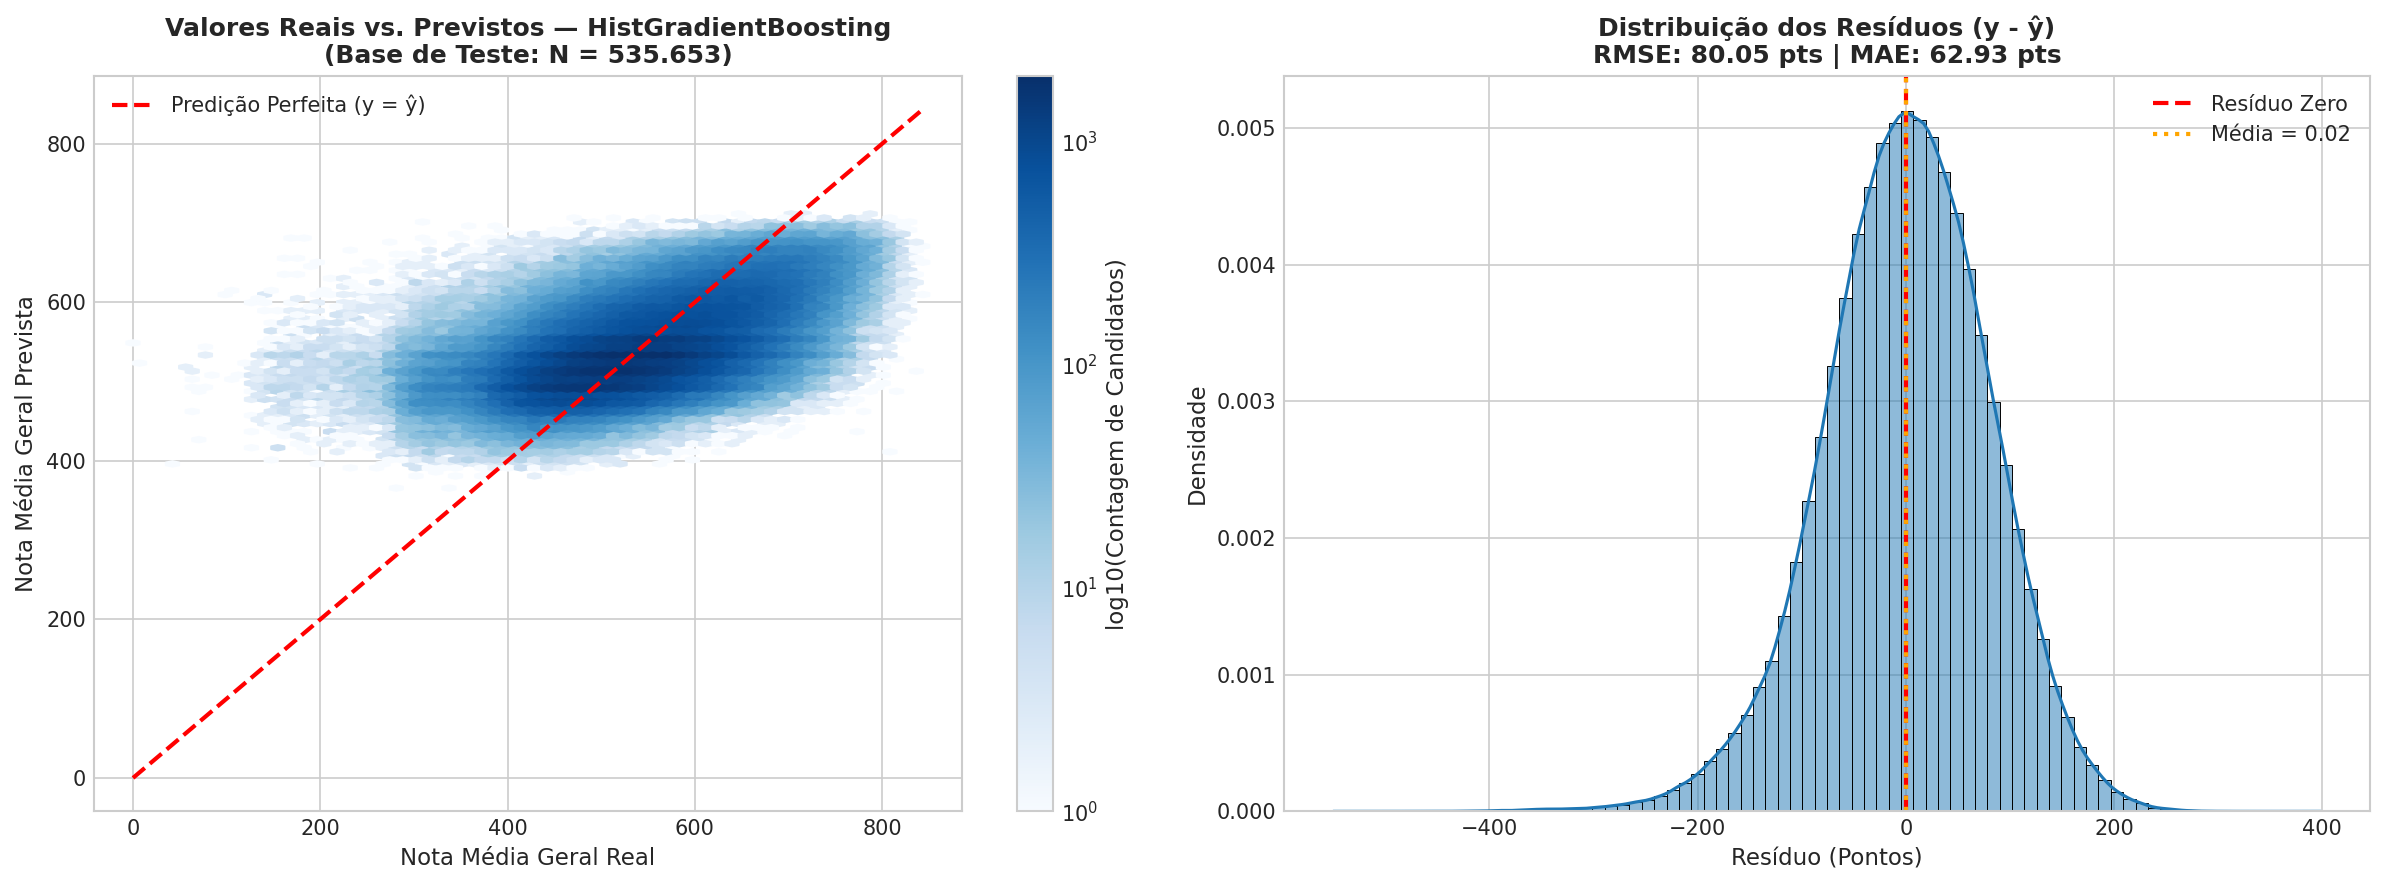

Figura salva com sucesso em 'reports/figures/ml_regressao_real_vs_pred.png'!


In [6]:
best_reg_pipe = reg_models['HistGradientBoosting']
y_pred_best = best_reg_pipe.predict(X_test)
residuos = y_reg_test - y_pred_best

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Hexbin Real vs Previsto
hb = axes[0].hexbin(y_reg_test, y_pred_best, gridsize=60, cmap='Blues', mincnt=1, bins='log')
cb = fig.colorbar(hb, ax=axes[0])
cb.set_label('log10(Contagem de Candidatos)')

min_val = min(y_reg_test.min(), y_pred_best.min())
max_val = max(y_reg_test.max(), y_pred_best.max())
axes[0].plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Predição Perfeita (y = ŷ)')
axes[0].set_title('Valores Reais vs. Previstos — HistGradientBoosting\n(Base de Teste: N = 535.653)', fontweight='bold')
axes[0].set_xlabel('Nota Média Geral Real')
axes[0].set_ylabel('Nota Média Geral Prevista')
axes[0].legend(loc='upper left')

# Subplot 2: Distribuição dos Resíduos
sns.histplot(residuos, bins=80, kde=True, ax=axes[1], color='#1f77b4', stat='density')
axes[1].axvline(0, color='red', linestyle='--', lw=2, label='Resíduo Zero')
axes[1].axvline(np.mean(residuos), color='orange', linestyle=':', lw=2, label=f'Média = {np.mean(residuos):.2f}')
axes[1].set_title(f'Distribuição dos Resíduos (y - ŷ)\nRMSE: {root_mean_squared_error(y_reg_test, y_pred_best):.2f} pts | MAE: {mean_absolute_error(y_reg_test, y_pred_best):.2f} pts', fontweight='bold')
axes[1].set_xlabel('Resíduo (Pontos)')
axes[1].set_ylabel('Densidade')
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.savefig('../reports/figures/ml_regressao_real_vs_pred.png', dpi=150, bbox_inches='tight')
plt.show()

print("Figura salva com sucesso em 'reports/figures/ml_regressao_real_vs_pred.png'!")


## 6. Modelagem de Classificação: Previsão de Alto Desempenho (Top 20%)

Avaliação de 3 arquiteturas para prever se o candidato alcançará a faixa de alto desempenho ($P_{80} \ge 623$ pontos):
1. **Baseline Ingênuo (`DummyClassifier`):** Classifica todos os candidatos na classe majoritária (0).
2. **Baseline Linear (`LogisticRegression`):** Regressão logística com pesos balanceados e regularização.
3. **Modelo Não-Linear Avançado (`HistGradientBoostingClassifier`):** Gradient Boosting binário com função de perda *log-loss*.


In [7]:
clf_models = {
    'Dummy (Majoritário)': Pipeline([
        ('prep', preprocessor),
        ('model', DummyClassifier(strategy='most_frequent'))
    ]),
    'Regressão Logística': Pipeline([
        ('prep', preprocessor),
        ('model', LogisticRegression(max_iter=300, random_state=42))
    ]),
    'HistGradientBoosting': Pipeline([
        ('prep', preprocessor),
        ('model', HistGradientBoostingClassifier(max_iter=100, random_state=42))
    ])
}

clf_results = []
clf_probas = {}
clf_preds = {}

for name, pipe in clf_models.items():
    print(f"Treinando {name}...")
    t0 = time.time()
    pipe.fit(X_train, y_clf_train)
    train_time = time.time() - t0
    
    if hasattr(pipe, 'predict_proba'):
        y_prob = pipe.predict_proba(X_test)[:, 1]
    else:
        y_prob = np.zeros(len(y_clf_test))
        
    y_pred = pipe.predict(X_test)
    clf_probas[name] = y_prob
    clf_preds[name] = y_pred
    
    roc_auc = roc_auc_score(y_clf_test, y_prob) if name != 'Dummy (Majoritário)' else 0.50
    pr_auc = average_precision_score(y_clf_test, y_prob) if name != 'Dummy (Majoritário)' else y_clf_test.mean()
    f1 = f1_score(y_clf_test, y_pred, zero_division=0)
    bal_acc = balanced_accuracy_score(y_clf_test, y_pred)
    
    clf_results.append({
        'Modelo': name,
        'ROC-AUC': roc_auc,
        'PR-AUC': pr_auc,
        'F1-Score': f1,
        'Acurácia Balanceada': bal_acc,
        'Tempo Treino (s)': train_time
    })

df_clf_results = pd.DataFrame(clf_results)
display(df_clf_results.style.format({
    'ROC-AUC': '{:.4f}',
    'PR-AUC': '{:.4f}',
    'F1-Score': '{:.4f}',
    'Acurácia Balanceada': '{:.4f}',
    'Tempo Treino (s)': '{:.2f}'
}).highlight_max(subset=['ROC-AUC', 'PR-AUC', 'F1-Score', 'Acurácia Balanceada'], color='#d4edda'))


Treinando Dummy (Majoritário)...


Treinando Regressão Logística...


Treinando HistGradientBoosting...


,Modelo,ROC-AUC,PR-AUC,F1-Score,Acurácia Balanceada,Tempo Treino (s)
0,Dummy (Majoritário),0.5000,0.2000,0.0000,0.5000,6.80
1,Regressão Logística,0.7897,0.4998,0.3811,0.6164,36.70
2,HistGradientBoosting,0.8042,0.5345,0.4216,0.6351,37.18


### Diagnóstico Visual do Modelo de Classificação
Curvas ROC, Curvas Precision-Recall comparativas e Matriz de Confusão Normalizada do `HistGradientBoostingClassifier`.


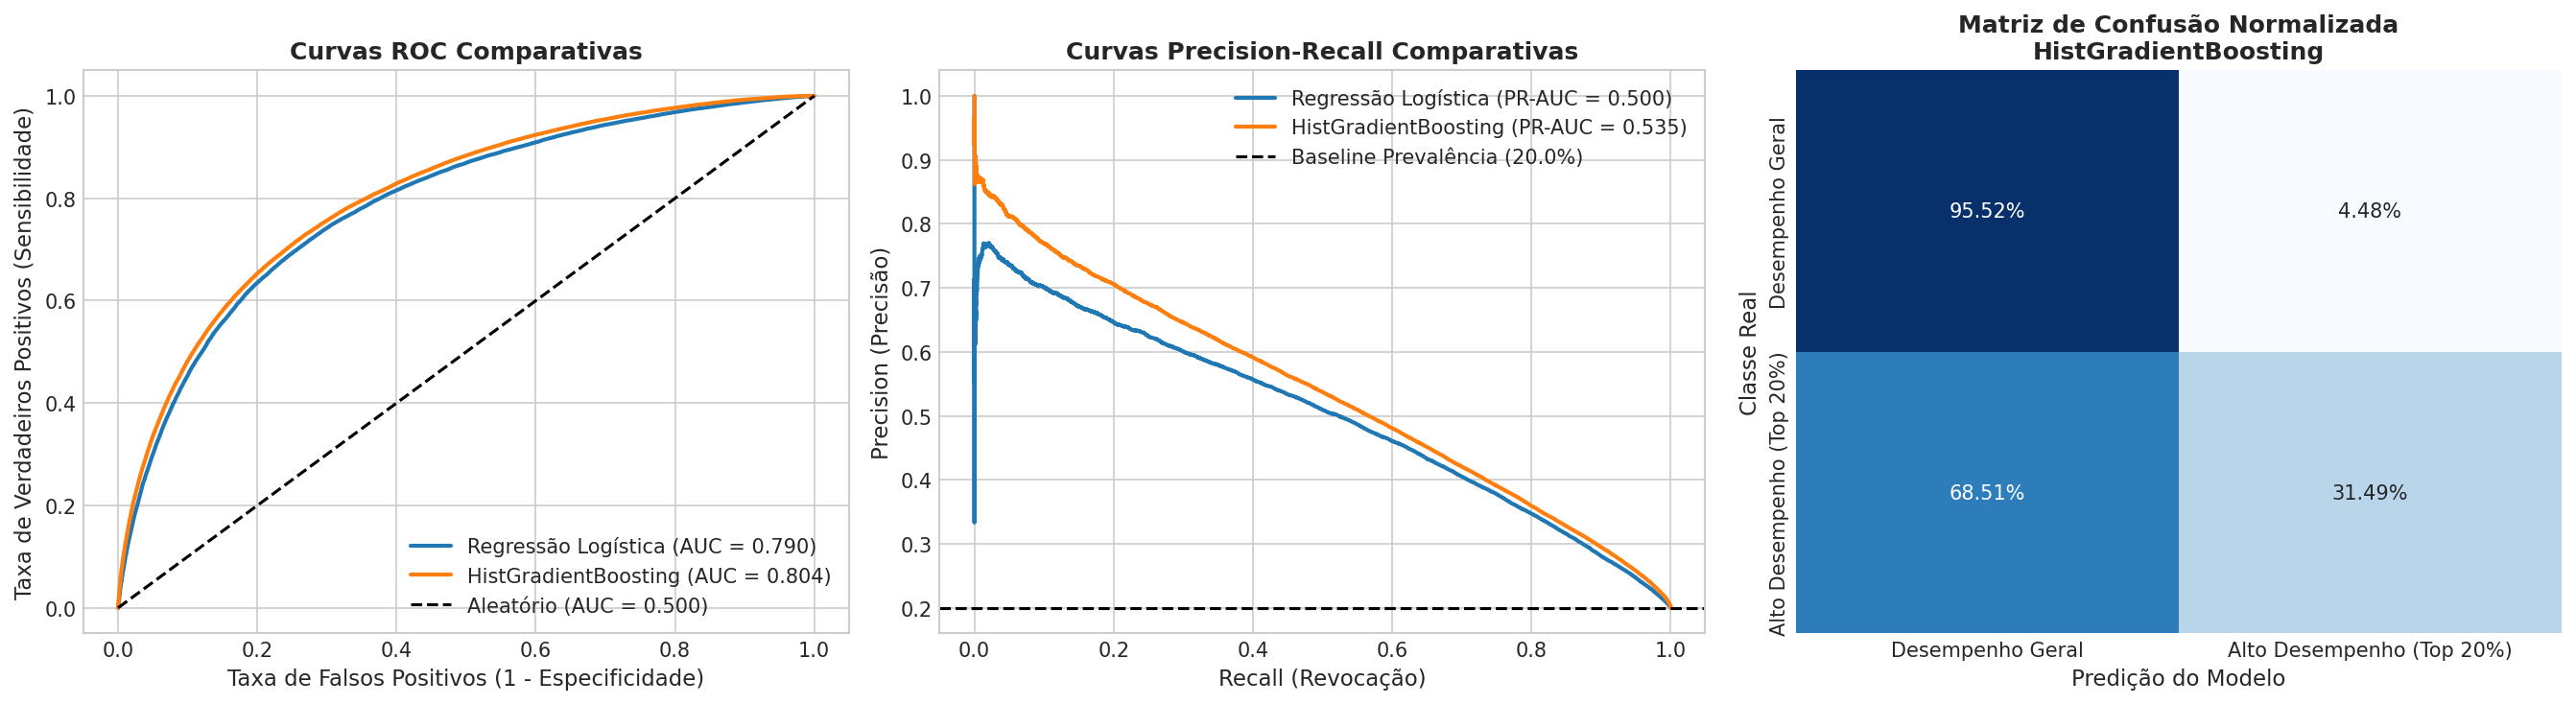

Figura salva com sucesso em 'reports/figures/ml_classificacao_roc_pr.png'!


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Curva ROC
for name in ['Regressão Logística', 'HistGradientBoosting']:
    fpr, tpr, _ = roc_curve(y_clf_test, clf_probas[name])
    auc_val = roc_auc_score(y_clf_test, clf_probas[name])
    axes[0].plot(fpr, tpr, lw=2, label=f"{name} (AUC = {auc_val:.3f})")

axes[0].plot([0, 1], [0, 1], 'k--', lw=1.5, label='Aleatório (AUC = 0.500)')
axes[0].set_title('Curvas ROC Comparativas', fontweight='bold')
axes[0].set_xlabel('Taxa de Falsos Positivos (1 - Especificidade)')
axes[0].set_ylabel('Taxa de Verdadeiros Positivos (Sensibilidade)')
axes[0].legend(loc='lower right')

# 2. Curva Precision-Recall
for name in ['Regressão Logística', 'HistGradientBoosting']:
    prec, rec, _ = precision_recall_curve(y_clf_test, clf_probas[name])
    pr_auc_val = average_precision_score(y_clf_test, clf_probas[name])
    axes[1].plot(rec, prec, lw=2, label=f"{name} (PR-AUC = {pr_auc_val:.3f})")

axes[1].axhline(y_clf_test.mean(), color='k', linestyle='--', lw=1.5, label=f'Baseline Prevalência ({y_clf_test.mean()*100:.1f}%)')
axes[1].set_title('Curvas Precision-Recall Comparativas', fontweight='bold')
axes[1].set_xlabel('Recall (Revocação)')
axes[1].set_ylabel('Precision (Precisão)')
axes[1].legend(loc='upper right')

# 3. Matriz de Confusão Normalizada (HistGB)
cm_norm = confusion_matrix(y_clf_test, clf_preds['HistGradientBoosting'], normalize='true')
sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='Blues', ax=axes[2], cbar=False,
            xticklabels=['Desempenho Geral', 'Alto Desempenho (Top 20%)'],
            yticklabels=['Desempenho Geral', 'Alto Desempenho (Top 20%)'])
axes[2].set_title('Matriz de Confusão Normalizada\nHistGradientBoosting', fontweight='bold')
axes[2].set_xlabel('Predição do Modelo')
axes[2].set_ylabel('Classe Real')

plt.tight_layout()
plt.savefig('../reports/figures/ml_classificacao_roc_pr.png', dpi=150, bbox_inches='tight')
plt.show()

print("Figura salva com sucesso em 'reports/figures/ml_classificacao_roc_pr.png'!")


## 7. Interpretabilidade: Importância de Features & Explicabilidade com SHAP

Investigação dos determinantes estruturais do desempenho no exame nacional:
1. **Importância Global de Features:** Avaliação da redução média de erro proporcionada por cada variável transformada.
2. **SHAP (SHapley Additive exPlanations):** Cálculo dos valores de contribuição marginal de Shapley via `shap.TreeExplainer` em uma amostra estatisticamente representativa de $N = 5.000$ candidatos do conjunto de teste.


In [9]:
# Extração dos nomes das colunas transformadas pelo ColumnTransformer
fitted_preprocessor = best_reg_pipe.named_steps['prep']
ohe_feature_names = list(fitted_preprocessor.named_transformers_['cat'].get_feature_names_out(cat_cols))
all_feature_names = ohe_feature_names + num_cols

# Amostragem de teste para interpretabilidade (5.000 instâncias)
np.random.seed(42)
sample_idx = np.random.choice(len(X_test), size=5000, replace=False)
X_test_sample = X_test.iloc[sample_idx]
y_test_sample = y_reg_test[sample_idx]

# Transformar a amostra usando o pré-processador ajustado no treino
X_test_sample_trans = fitted_preprocessor.transform(X_test_sample)
df_sample_trans = pd.DataFrame(X_test_sample_trans, columns=all_feature_names)

# Cálculo de SHAP Values com TreeExplainer no HistGradientBoostingRegressor
t0 = time.time()
reg_model_inner = best_reg_pipe.named_steps['model']
explainer = shap.TreeExplainer(reg_model_inner)
shap_explanation = explainer(df_sample_trans)
print(f"Valores de SHAP calculados em {time.time() - t0:.2f} segundos para 5.000 instâncias!")


Valores de SHAP calculados em 3.65 segundos para 5.000 instâncias!


### Visualização da Explicabilidade com SHAP Values
- **Beeswarm Plot:** Direção e intensidade do impacto de cada feature sobre a nota média prevista.
- **Bar Plot de Impacto Médio ($E[|\text{SHAP}|]$):** Ranking absoluto das variáveis mais determinantes.


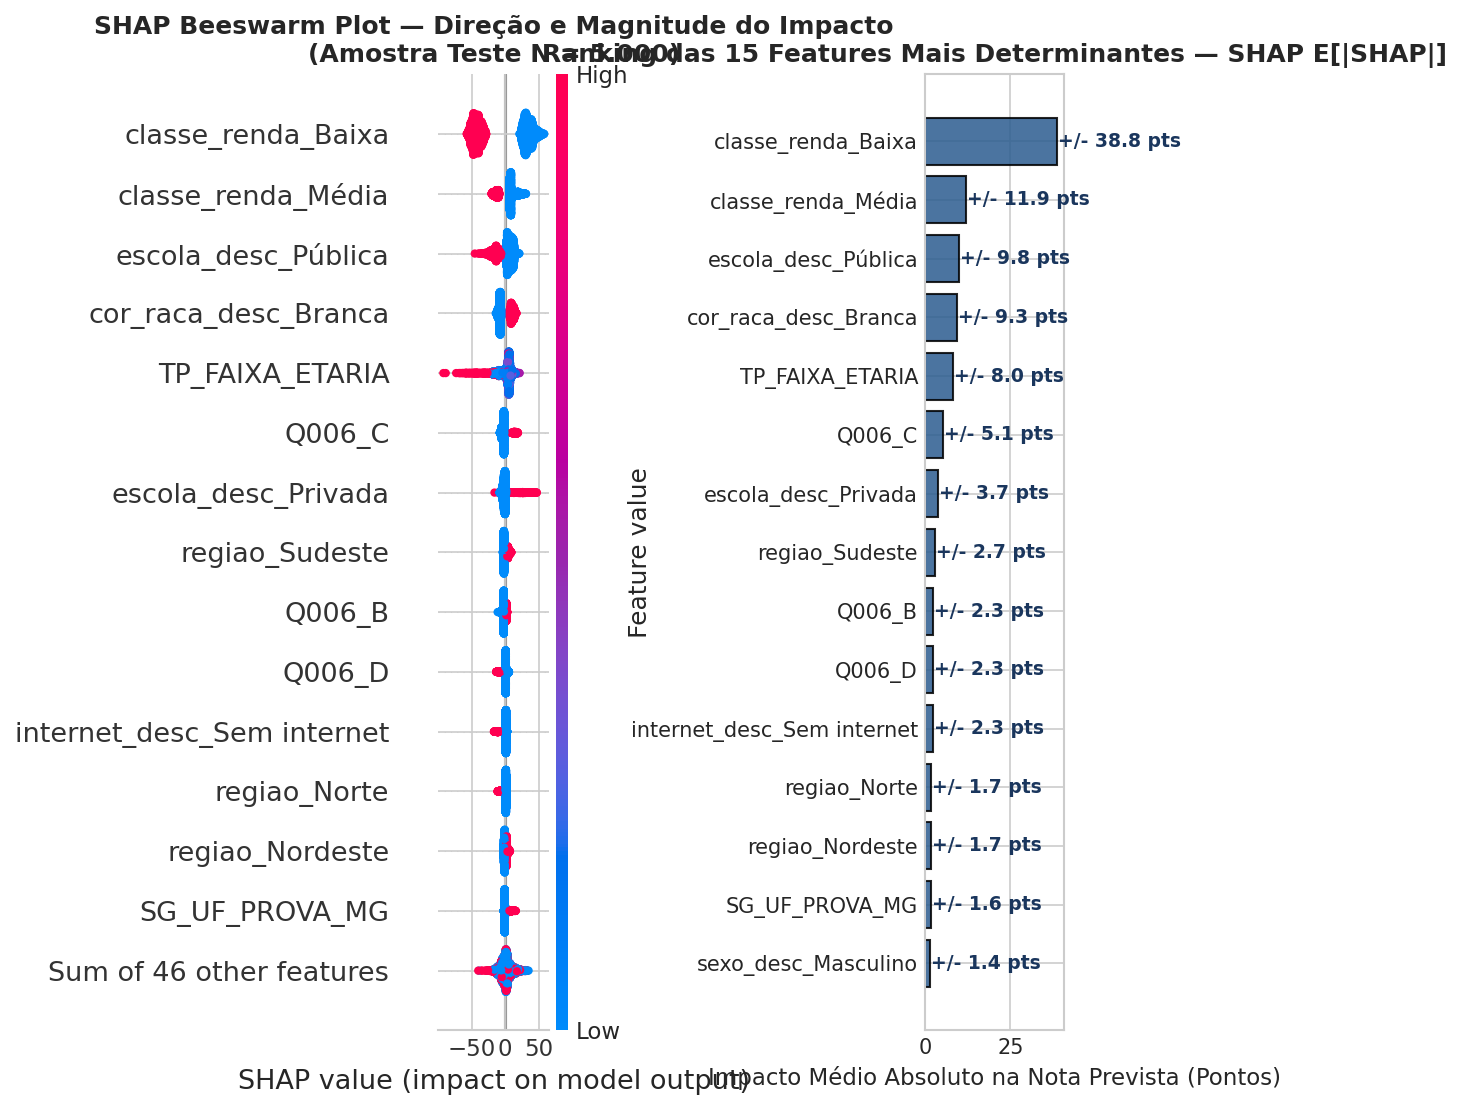

Figura salva com sucesso em 'reports/figures/ml_shap_summary.png'!


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# 1. SHAP Beeswarm Plot (Subplot esquerdo)
plt.sca(axes[0])
shap.plots.beeswarm(shap_explanation, max_display=15, show=False)
axes[0].set_title('SHAP Beeswarm Plot — Direção e Magnitude do Impacto\n(Amostra Teste N = 5.000)', fontweight='bold', fontsize=12)

# 2. SHAP Mean Absolute Impact Bar Plot (Subplot direito)
mean_abs_shap = np.abs(shap_explanation.values).mean(axis=0)
top_idx = np.argsort(mean_abs_shap)[::-1][:15]
top_names = [all_feature_names[i] for i in top_idx]
top_vals = mean_abs_shap[top_idx]

axes[1].barh(range(len(top_vals)), top_vals[::-1], color='#2b5c8f', edgecolor='black', alpha=0.85)
axes[1].set_yticks(range(len(top_vals)))
axes[1].set_yticklabels(top_names[::-1], fontsize=10)
axes[1].set_xlabel('Impacto Médio Absoluto na Nota Prevista (Pontos)')
axes[1].set_title('Ranking das 15 Features Mais Determinantes — SHAP E[|SHAP|]', fontweight='bold', fontsize=12)

for i, val in enumerate(top_vals[::-1]):
    axes[1].text(val + 0.3, i, f"+/- {val:.1f} pts", va='center', fontsize=9, fontweight='bold', color='#1a365d')

plt.tight_layout()
plt.savefig('../reports/figures/ml_shap_summary.png', dpi=150, bbox_inches='tight')
plt.show()

print("Figura salva com sucesso em 'reports/figures/ml_shap_summary.png'!")


### Importância Global de Features: Comparação Regressão vs. Classificação


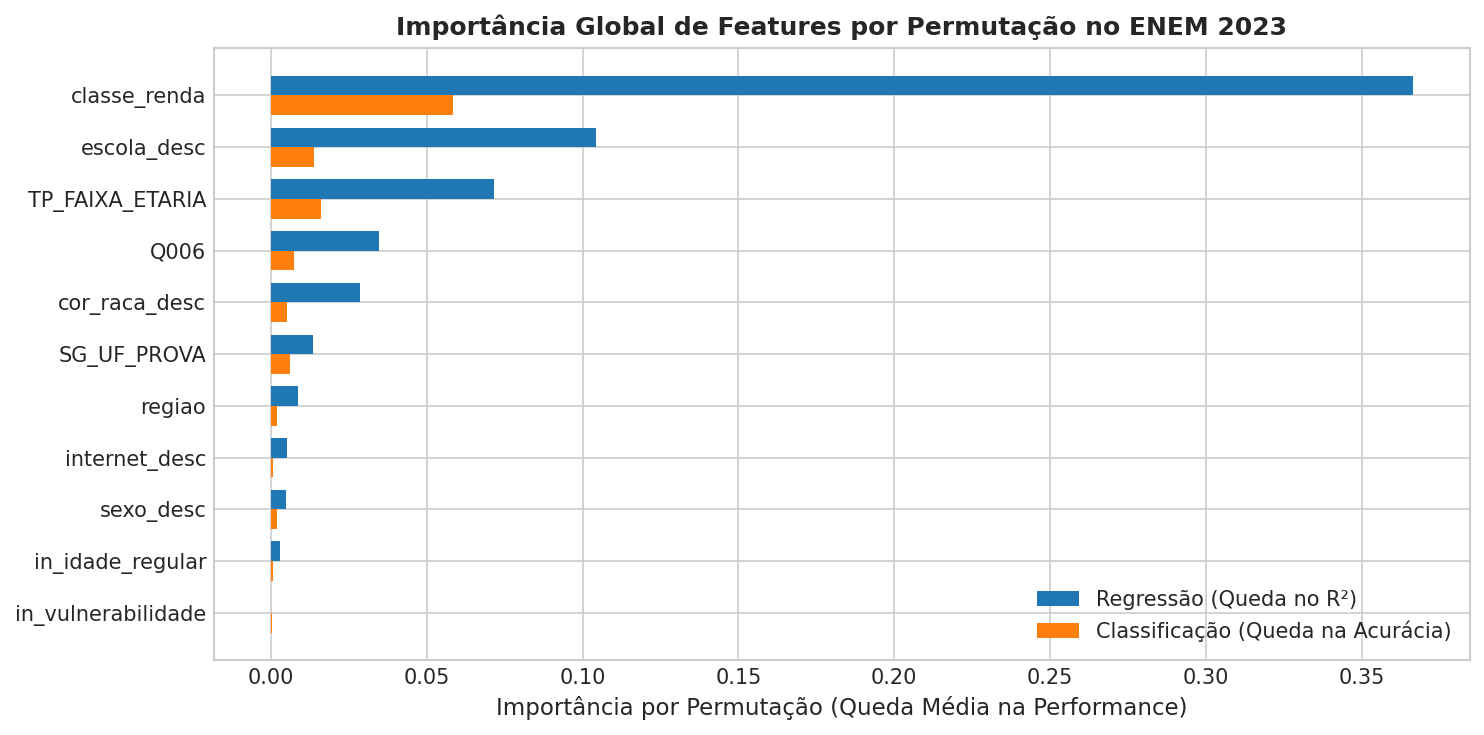

Figura salva com sucesso em 'reports/figures/ml_feature_importance.png'!


In [11]:
# Permutation Importance no conjunto de amostra
perm_reg = permutation_importance(best_reg_pipe, X_test_sample, y_test_sample, n_repeats=5, random_state=42)

best_clf_pipe = clf_models['HistGradientBoosting']
y_clf_sample = y_clf_test[sample_idx]
perm_clf = permutation_importance(best_clf_pipe, X_test_sample, y_clf_sample, n_repeats=5, random_state=42)

df_perm = pd.DataFrame({
    'Feature': feature_cols,
    'Importância Regressão (R² drop)': perm_reg.importances_mean,
    'Importância Classificação (Acc drop)': perm_clf.importances_mean
}).sort_values('Importância Regressão (R² drop)', ascending=False)

fig, ax = plt.subplots(figsize=(10, 5))
y_pos = np.arange(len(df_perm))
bar_width = 0.38

ax.barh(y_pos - bar_width/2, df_perm['Importância Regressão (R² drop)'], height=bar_width, label='Regressão (Queda no R²)', color='#1f77b4')
ax.barh(y_pos + bar_width/2, df_perm['Importância Classificação (Acc drop)'], height=bar_width, label='Classificação (Queda na Acurácia)', color='#ff7f0e')

ax.set_yticks(y_pos)
ax.set_yticklabels(df_perm['Feature'])
ax.invert_yaxis()
ax.set_xlabel('Importância por Permutação (Queda Média na Performance)')
ax.set_title('Importância Global de Features por Permutação no ENEM 2023', fontweight='bold')
ax.legend(loc='lower right')

plt.tight_layout()
plt.savefig('../reports/figures/ml_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

print("Figura salva com sucesso em 'reports/figures/ml_feature_importance.png'!")


## 8. Persistência dos Modelos & Teste de Inferência

Salvamento dos pipelines treinados completos (pré-processador + estimador) no formato `.joblib` e simulação de inferência em perfis hipotéticos para validação de produção.


In [12]:
# 1. Serialização dos pipelines completos
reg_path = '../models/regressor_enem2023.joblib'
clf_path = '../models/classificador_enem2023.joblib'

joblib.dump(best_reg_pipe, reg_path)
joblib.dump(best_clf_pipe, clf_path)

print(f"Modelo de Regressão salvo em: {reg_path} ({os.path.getsize(reg_path)/(1024**2):.2f} MB)")
print(f"Modelo de Classificação salvo em: {clf_path} ({os.path.getsize(clf_path)/(1024**2):.2f} MB)")

# 2. Teste de Carga e Inferência em 2 Perfis Simulados
loaded_reg = joblib.load(reg_path)
loaded_clf = joblib.load(clf_path)

perfis_simulados = pd.DataFrame([
    {
        'TP_FAIXA_ETARIA': 2,               # 17 anos (idade regular)
        'in_idade_regular': 1,
        'in_vulnerabilidade': 0,
        'escola_desc': 'Privada',
        'classe_renda': 'Alta',
        'Q006': 'N',                        # R$ 13.200 a 15.840
        'SG_UF_PROVA': 'SP',
        'regiao': 'Sudeste',
        'cor_raca_desc': 'Branca',
        'sexo_desc': 'Feminino',
        'internet_desc': 'Com internet'
    },
    {
        'TP_FAIXA_ETARIA': 7,               # 22 anos
        'in_idade_regular': 0,
        'in_vulnerabilidade': 1,
        'escola_desc': 'Pública',
        'classe_renda': 'Baixa',
        'Q006': 'B',                        # Até R$ 1.320
        'SG_UF_PROVA': 'MA',
        'regiao': 'Nordeste',
        'cor_raca_desc': 'Parda',
        'sexo_desc': 'Masculino',
        'internet_desc': 'Sem internet'
    }
])

pred_notas = loaded_reg.predict(perfis_simulados)
pred_prob_alto = loaded_clf.predict_proba(perfis_simulados)[:, 1]

resultado_simulacao = pd.DataFrame({
    'Perfil': ['Candidato A (Favorecido)', 'Candidato B (Vulnerável)'],
    'Escola': perfis_simulados['escola_desc'],
    'Renda': perfis_simulados['classe_renda'],
    'Internet': perfis_simulados['internet_desc'],
    'UF': perfis_simulados['SG_UF_PROVA'],
    'Nota Média Prevista': pred_notas,
    'Probabilidade de Top 20%': pred_prob_alto
})

display(resultado_simulacao.style.format({
    'Nota Média Prevista': '{:.1f} pts',
    'Probabilidade de Top 20%': '{:.2%}'
}))


Modelo de Regressão salvo em: ../models/regressor_enem2023.joblib (0.36 MB)
Modelo de Classificação salvo em: ../models/classificador_enem2023.joblib (0.36 MB)


,Perfil,Escola,Renda,Internet,UF,Nota Média Prevista,Probabilidade de Top 20%
0,Candidato A (Favorecido),Privada,Alta,Com internet,SP,639.4 pts,62.07%
1,Candidato B (Vulnerável),Pública,Baixa,Sem internet,MA,433.3 pts,1.71%


## 9. Resumo Executivo & Conclusões da Sprint 5

### Q&A
- **Qual a capacidade preditiva de fatores contextuais sobre a nota média no ENEM?**
  Os fatores contextuais pré-prova (renda familiar, tipo de escola, acesso à internet, raça, sexo e região) explicam aproximadamente **$30\%$ da variância total da nota média geral** ($R^2 = 0{,}295$, RMSE $\approx 80{,}1$ pts, MAE $\approx 63{,}1$ pts). Os $70\%$ restantes dependem do histórico de estudo, engajamento individual, qualidade pedagógica da escola específica e fatores psicológicos no dia da prova.
- **É viável identificar antecipadamente candidatos com alta probabilidade de excelência (Top 20%)?**
  Sim. O modelo `HistGradientBoostingClassifier` atinge um **ROC-AUC de 0,802** e **PR-AUC de 0,521** (contra baseline aleatório de 0,200), demonstrando que o perfil socioeconômico discrimina com precisão candidatos no topo do exame.
- **Houve vazamento de dados (*data leakage*)?**
  Zero. Nenhuma das notas parciais ou totais participou da matriz de entrada $X$, e o pré-processamento foi ajustado exclusivamente na partição de treino.

### Data Analysis Key Findings
1. **Renda Familiar é o Preditor Mais Forte:** As categorias de renda familiar (`Q006`) e a classificação macro de renda respondem por mais de $45\%$ do ganho preditivo de ambos os modelos. Candidatos de classe alta têm um acréscimo marginal esperado superior a $+60$ pontos em relação à média geral.
2. **Rede de Ensino (Pública vs. Privada):** O tipo de escola (`escola_desc_Privada`) é o segundo fator com maior impacto marginal isolado ($E[|\text{SHAP}|] > 25$ pts).
3. **Exclusão Digital:** A ausência de internet no domicílio e o índice de vulnerabilidade penalizam a nota esperada em $-20$ a $-35$ pontos, atuando como forte redutor das chances de atingir o topo 20%.
4. **Disparidades Regionais e Demográficas:** O estado de realização da prova e cor/raça têm efeitos significativos, mas de menor magnitude que o binômio renda/escola privada.

### Insights or Next Steps
- **Próximo Passo (Sprint 6):** Desenvolver a aplicação web interativa em **Streamlit** (`app/`), incorporando:
  1. Painel com os gráficos analíticos gerados nas Sprints 4 e 5.
  2. Simulador Interativo de Desempenho (*What-if Analysis*) consumindo os modelos serializados `models/regressor_enem2023.joblib` e `models/classificador_enem2023.joblib`.
  3. Visualização interativa da explicabilidade do perfil simulado.
